# ToolLens: проверка Family CF и итоговое сравнение

        Реальные локальные данные и готовые train/val/test из requests.parquet.
        Сетка Family CF и правило выбора топ-3 фиксируются до расчёта метрик.
        Готовый val используется для выбора Family CF. Запросы сохраняют исходное назначение;
        для пересекающихся групп близких запросов действует приоритет test → val → train.
        Запросы с меньшим приоритетом исключаются из эксперимента. Один seed ограничивает
        обобщаемость выводов.

In [1]:
# Окружение задаётся до импорта численных библиотек и энкодера.
import os
from pathlib import Path
ROOT = Path.cwd()
if not (ROOT / 'rankers').exists():
    ROOT = next(path for path in Path.cwd().parents if (path / 'rankers').exists())
RUNTIME = ROOT / 'output/jupyter-notebook/runtime'
for name, folder in [('MPLCONFIGDIR', 'mpl'), ('XDG_CACHE_HOME', 'cache'), ('IPYTHONDIR', 'ipython')]:
    location = RUNTIME / folder
    location.mkdir(parents=True, exist_ok=True)
    os.environ[name] = str(location)
for name in ['OMP_NUM_THREADS', 'OPENBLAS_NUM_THREADS', 'MKL_NUM_THREADS', 'VECLIB_MAXIMUM_THREADS', 'NUMEXPR_NUM_THREADS']:
    os.environ[name] = '4'
os.environ.update(USE_TF='0', USE_FLAX='0', USE_TORCH='1',
                  HF_HUB_OFFLINE='1', TRANSFORMERS_OFFLINE='1', TOKENIZERS_PARALLELISM='false')
import sys, json, platform, subprocess, time, uuid
from datetime import datetime, timezone
sys.path.insert(0, str(ROOT))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
from tqdm.auto import tqdm
from IPython.display import display
from threadpoolctl import threadpool_limits
torch.set_num_threads(4)
THREAD_LIMIT = threadpool_limits(limits=4)
from experiments.toollens_experiment import (validate_tables, near_duplicate_groups,
    query_metrics, bootstrap_metrics, PeakRSS, file_sha256, json_hash)
from experiments.toollens_family_validation import family_neighbors, family_validation_curves
from rankers.popularity import PopularityRanker
from rankers.bm25 import BM25Ranker
from rankers.bge import ZeroShotBGERanker
from rankers.query_knn_cf import QueryKNNCFRanker
from rankers.family_query_knn_cf import FamilyQueryKNNCFRanker
from rankers.projected_query_cf import ProjectedQueryCFRanker

## Замороженный план

        Popularity, BM25 и BGE сравниваются с Query-KNN CF, Family CF и Projected CF.
        Для Family CF проверяем MiniBatchKMeans с 32, 64 и 128 кластерами и DBSCAN.
        Агрегация меток внутри семейства: binary (0/1),
        число позитивных запросов (count), sqrt(count) и log1p(count).
        Для каждой кластеризации и агрегации проверяем MSE, BPR/random и BPR/semantic.
        MSE учитывает все нулевые train-пары. BGE используется с замороженными весами.
        BPR/random выбирает негативы равномерно среди train API без позитивной связи.
        BPR/semantic следует текущему CF-протоколу: выбирает среди H наиболее далёких
        допустимых train API (минимальный cosine), а не среди ближайших hard negatives.
        Для BPR исключаются все позитивы семейства. Если ни у одного семейства нет
        одновременно позитива и негатива, конфигурация отмечается как неприменимая.
        Каждый шумовой запрос DBSCAN образует собственное семейство.
        На готовом val сравниваем по FullCoverage@10, затем Recall@10, NDCG@10 и имени.
        Для каждого fit проверяем 1, 2, 3, 5 и 10 соседей. Три лучшие конфигурации
        повторно обучаем на том же train и сравниваем с остальными моделями на общем test.
        Macro Recall, бинарный NDCG и FullCoverage строятся для K=1…20.
        Для K=3,5,10,20: парный bootstrap (1000, seed=68) и разности относительно BGE.
        Запросы без позитивов исключаются из средних с отдельным счётчиком.

In [2]:
SEED = 67
PROTOCOL = 'ToolLens-provided-splits-family-minibatch-v5'
SPLIT_PRIORITY = ('train', 'val', 'test')
FAMILY_NEIGHBORS = (1, 2, 3, 5, 10)
FAMILY_TOP_N = 3
MODEL_PATH = ROOT / 'models/bge-small-en-v1.5'
INSTRUCTION = 'Represent this sentence for searching relevant passages: '
CF_COMMON = dict(factors=16, epochs=5, regularization=.1,
    positive_weight=1., n_neighbors=10, neighbor_weighting='cosine',
    seed=SEED, device='cpu', encoder_device='cpu', learning_rate=.01,
    batch_size=128, query_instruction=INSTRUCTION, max_length=512, encoder_batch_size=32)
CONFIGS = {
    'Popularity': {}, 'BM25': dict(k1=1.5, b=.75),
    'BGE': dict(model_path=str(MODEL_PATH), device='cpu', max_length=512,
                batch_size=32, query_instruction=INSTRUCTION),
}
FACTORIES = {'Popularity': PopularityRanker, 'BM25': BM25Ranker, 'BGE': ZeroShotBGERanker}
CF_FAMILIES = {
    'Query-KNN CF': (QueryKNNCFRanker, {}),
    'Projected CF': (ProjectedQueryCFRanker, {}),
}
BPR_COMMON = dict(negatives_per_positive=1, hard_pool_size=20)
CF_OBJECTIVES = {
    'MSE': dict(loss='mse'),
    'BPR/random': dict(loss='bpr', negative_sampling='random', **BPR_COMMON),
    'BPR/semantic': dict(loss='bpr', negative_sampling='semantic', **BPR_COMMON),
}
VARIANTS = {name: dict(family=name, loss=None, negative_sampling=None) for name in CONFIGS}
for family, (factory, family_config) in CF_FAMILIES.items():
    for objective, objective_config in CF_OBJECTIVES.items():
        name = f'{family} | {objective}'
        CONFIGS[name] = dict(CF_COMMON, **family_config, **objective_config)
        FACTORIES[name] = factory
        VARIANTS[name] = dict(family=family, loss=objective_config['loss'],
                              negative_sampling=objective_config.get('negative_sampling'))
FAMILY_CLUSTERINGS = {
    'MiniBatchKMeans-32': dict(clustering='minibatch_kmeans', n_families=32),
    'MiniBatchKMeans-64': dict(clustering='minibatch_kmeans', n_families=64),
    'MiniBatchKMeans-128': dict(clustering='minibatch_kmeans', n_families=128),
    'DBSCAN ε=0.2, min=5': dict(clustering='dbscan', eps=.2, min_samples=5),
}
FAMILY_RELEVANCE = {
    'binary': dict(aggregation='binary'),
    **{transform: dict(aggregation='frequency', count_transform=transform)
       for transform in ('count', 'sqrt', 'log1p')},
}
FAMILY_FIT_CONFIGS = {
    (clustering, relevance, objective): {
        **CF_COMMON, **clustering_config, **relevance_config, **objective_config,
    }
    for clustering, clustering_config in FAMILY_CLUSTERINGS.items()
    for relevance, relevance_config in FAMILY_RELEVANCE.items()
    for objective, objective_config in CF_OBJECTIVES.items()
}
RUN_DIR = ROOT / 'output/jupyter-notebook/runs' / (datetime.now(timezone.utc).strftime('%Y%m%dT%H%M%SZ') + '_' + uuid.uuid4().hex[:8])
RUN_DIR.mkdir(parents=True, exist_ok=False)
family_plan = dict(validation_split='val', neighbors=FAMILY_NEIGHBORS,
    top_n=FAMILY_TOP_N, selection_k=10, selection_order=['FullCoverage', 'Recall', 'NDCG'],
    fits={' | '.join(labels): config for labels, config in FAMILY_FIT_CONFIGS.items()})
(RUN_DIR / 'family_search_space.json').write_text(
    json.dumps(family_plan, ensure_ascii=False, indent=2), encoding='utf-8')
print(f'Family CF: {len(FAMILY_FIT_CONFIGS)} обучений, '
      f'{len(FAMILY_FIT_CONFIGS) * len(FAMILY_NEIGHBORS)} вариантов инференса')
print('Run:', RUN_DIR)

Family CF: 48 обучений, 240 вариантов инференса
Run: /Users/svatoslavpolonskiy/Codex/CFTSagent/output/jupyter-notebook/runs/20261119T090314Z_f80bbec0


## Данные и проверки

        Исходные таблицы читаются без изменения. Некорректные ID, ссылки, пустые тексты,
        повторные пары и нечисловые метки завершают запуск ошибкой. Никакие строки не исключаются молча.

In [3]:
DATA_DIR = ROOT / 'data/ToolLens/processed'
tables = {}
with PeakRSS() as measurement:
    for name in tqdm(['apis', 'requests', 'interactions'], desc='Чтение Parquet'):
        tables[name] = pd.read_parquet(DATA_DIR / (name + '.parquet'))
    apis, requests, interactions = (tables[name] for name in ['apis', 'requests', 'interactions'])
    validation = validate_tables(apis, requests, interactions)
resources = {'load_and_validate': measurement.record()}
data_hashes = {name: file_sha256(DATA_DIR / (name + '.parquet')) for name in tables}
if 'split' not in requests or set(requests['split']) != set(SPLIT_PRIORITY):
    raise ValueError('В requests.parquet должны присутствовать готовые train, val и test')
requests = requests.rename(columns={'split': 'source_split'}).copy()
display(pd.DataFrame([validation]))
display(requests.source_split.value_counts().rename('queries').to_frame())

Чтение Parquet:   0%|          | 0/3 [00:00<?, ?it/s]

,apis,requests,interactions,no_positive_queries
0,464,18770,49852,0


,queries
source_split,
train,15016
val,1877
test,1877


## Готовые сплиты и проверка близких запросов

        Unicode NFKC, casefold, токены `\w+`, цифры сохраняются. Exact prefix join с
        глобальным порядком редкости и фильтром размера проверяет все допустимые пары.
        Для каждой группы сохраняются запросы из сплита с наивысшим приоритетом
        (test, затем val, затем train). Остальные запросы группы и их связи исключаются.
        В split_ids.csv сохраняются исходный сплит, группировка и итоговый статус каждой строки.

In [4]:
with PeakRSS() as measurement:
    with tqdm(total=len(requests), desc='Точный near-duplicate join') as bar:
        groups = near_duplicate_groups(requests.Request_id.tolist(), requests.text.tolist(),
            threshold=.9, progress=lambda step, total: bar.update(step - bar.n))
resources['grouping'] = measurement.record()
requests['group_id'] = requests.Request_id.map(groups)
split_ranks = {split: rank for rank, split in enumerate(SPLIT_PRIORITY)}
ranks = requests.source_split.map(split_ranks)
group_ranks = ranks.groupby(requests.group_id).transform('max')
requests['group_split'] = group_ranks.map(dict(enumerate(SPLIT_PRIORITY)))
requests['split'] = requests.source_split.where(ranks == group_ranks, 'excluded')
active_requests = requests[requests.split != 'excluded']
assert active_requests.groupby('group_id')['split'].nunique().max() == 1
assert int(requests.split.eq('test').sum()) == int(requests.source_split.eq('test').sum())
split_audit = requests[['Request_id', 'group_id', 'source_split', 'split', 'group_split']].sort_values('Request_id')
split_hash = json_hash(list(split_audit.itertuples(index=False, name=None)))
split_audit.to_csv(RUN_DIR / 'split_ids.csv', index=False)
split_counts = pd.crosstab(requests.source_split, requests.split)
excluded_by_source = {part: int((requests.source_split.eq(part) & requests.split.eq('excluded')).sum())
                      for part in SPLIT_PRIORITY}
split_report = dict(source='requests.parquet:split', priority=list(reversed(SPLIT_PRIORITY)),
    used_queries={part: int(requests.split.eq(part).sum()) for part in SPLIT_PRIORITY},
    excluded_by_source=excluded_by_source)
group_sizes = requests.groupby('group_id').size()
display(split_counts)
print('Компонент >1 запроса:', int((group_sizes > 1).sum()), '; максимальная:', int(group_sizes.max()))
print('Split SHA256:', split_hash)
full_corpus = {int(row.API_id): {'description': row.description} for row in apis.itertuples(index=False)}
queries = {}
for part, frame in active_requests.sort_values('Request_id').groupby('split'):
    queries[part] = dict(zip(map(int, frame.Request_id), frame.text))
if set(queries) != set(SPLIT_PRIORITY):
    raise ValueError('После исключения пересечений нужны непустые train, val и test')
train_queries, val_queries, test_queries = (queries[part] for part in SPLIT_PRIORITY)
positives = {identifier: {} for partition in queries.values() for identifier in partition}
for row in interactions.itertuples(index=False):
    identifier = int(row.Request_id)
    if row.relevance > 0 and identifier in positives:
        positives[identifier][int(row.API_id)] = float(row.relevance)
train_qrels = {key: positives[key] for key in train_queries}
val_qrels = {key: set(positives[key]) for key in val_queries}
test_qrels = {key: set(positives[key]) for key in test_queries}
train_api_ids = set(api for links in train_qrels.values() for api in links)
train_corpus = {api: full_corpus[api] for api in sorted(train_api_ids)}
if not train_corpus or not any(val_qrels.values()) or not any(test_qrels.values()):
    raise ValueError('Нужны позитивные связи в каждом из сплитов train, val и test')
print('Train API / полный каталог:', len(train_corpus), '/', len(full_corpus))
print('Запросы без позитивов train/val/test:',
      *(sum(not links for links in qrels.values()) for qrels in (train_qrels, val_qrels, test_qrels)))

Точный near-duplicate join:   0%|          | 0/18770 [00:00<?, ?it/s]

split,excluded,test,train,val
source_split,,,,
test,0,1877,0,0
train,108,0,14908,0
val,7,0,0,1870


Компонент >1 запроса: 98 ; максимальная: 38
Split SHA256: d9b4b35d17f89acbc4bc0cda8103c2d88def493e79074462897eda13b0cab3ea
Train API / полный каталог: 464 / 464
Запросы без позитивов train/val/test: 0 0 0


## Один локальный замороженный энкодер

        Описания API и запросы train, val и test кодируются замороженным BGE.
        Каждый сплит получает отдельный кэш. Стоимость общего кодирования учитывается отдельно.
        Полный каталог доступен всем моделям, включая API без train-истории.

In [5]:
from sentence_transformers import SentenceTransformer
with PeakRSS() as measurement:
    encoder = SentenceTransformer(str(MODEL_PATH), device='cpu', local_files_only=True)
    encoder.max_seq_length = 512
resources['encoder_load'] = measurement.record()
def encode_cache(mapping, prefix, label):
    identifiers = sorted(mapping)
    batches = []
    for offset in tqdm(range(0, len(identifiers), 32), desc=label):
        ids = identifiers[offset:offset + 32]
        batch = encoder.encode([prefix + mapping[key] for key in ids],
            batch_size=32, show_progress_bar=False, convert_to_numpy=True)
        batches.append(np.asarray(batch, dtype=np.float32))
    matrix = np.concatenate(batches)
    return identifiers, matrix, {key: row for key, row in zip(identifiers, matrix)}
with PeakRSS() as measurement:
    api_ids, api_matrix, api_cache = encode_cache({key: doc['description'] for key, doc in full_corpus.items()}, '', 'API')
    train_ids, train_matrix, train_cache = encode_cache(train_queries, INSTRUCTION, 'Train-запросы')
    val_ids, val_matrix, val_cache = encode_cache(val_queries, INSTRUCTION, 'Val-запросы')
    test_ids, test_matrix, test_cache = encode_cache(test_queries, INSTRUCTION, 'Test-запросы (инференс)')
resources['shared_encoding'] = measurement.record()
np.savez_compressed(RUN_DIR / 'embeddings.npz', api_ids=api_ids, api_embeddings=api_matrix,
    train_ids=train_ids, train_embeddings=train_matrix, val_ids=val_ids, val_embeddings=val_matrix,
    test_ids=test_ids, test_embeddings=test_matrix)
lookup = {full_corpus[key]['description']: value for key, value in api_cache.items()}
lookup.update({INSTRUCTION + train_queries[key]: value for key, value in train_cache.items()})
lookup.update({INSTRUCTION + test_queries[key]: value for key, value in test_cache.items()})
class CachedEncoder:
    def encode(self, texts):
        return np.stack([lookup[text] for text in texts])
cached_encoder = CachedEncoder()

API:   0%|          | 0/15 [00:00<?, ?it/s]

Train-запросы:   0%|          | 0/466 [00:00<?, ?it/s]

Val-запросы:   0%|          | 0/59 [00:00<?, ?it/s]

Test-запросы (инференс):   0%|          | 0/59 [00:00<?, ?it/s]

## Отбор Family CF на готовом val

        На train обучаем 48 комбинаций кластеризации, агрегации и loss.
        Для каждого обучения считаем пять размеров окрестности с теми же факторами.
        Семейства и негативы для обучения строятся по train. На val используется
        полный каталог. Для диагностики сохраняем размер и плотность семейств.

In [6]:
train_api_cache = {key: api_cache[key] for key in train_corpus}
family_selection = dict(split_hash=split_hash, fit_split='train', selection_split='val',
    fit_queries=len(train_queries),
    validation_queries=len(val_qrels), evaluated_queries=sum(bool(links) for links in val_qrels.values()),
    excluded_no_positive_queries=sum(not links for links in val_qrels.values()))
display(pd.DataFrame([family_selection]))

,split_hash,fit_split,selection_split,fit_queries,validation_queries,evaluated_queries,excluded_no_positive_queries
0,d9b4b35d17f89acbc4bc0cda8103c2d88def493e790744...,train,val,14908,1870,1870,0


In [7]:
family_fit_rows, family_curve_rows, family_score_rows = [], [], []
validation_neighbors = None
for labels, config in tqdm(FAMILY_FIT_CONFIGS.items(), desc='Family CF · обучение на train'):
    clustering, relevance, objective = labels
    fit_id = ' | '.join(labels)
    metadata = dict(fit_id=fit_id, clustering=clustering, relevance=relevance, objective=objective)
    model = FamilyQueryKNNCFRanker(**config, encoder=cached_encoder)
    fit_kwargs = dict(train_queries=train_queries, train_query_embeddings=train_cache)
    if config.get('negative_sampling') == 'semantic':
        fit_kwargs['train_api_embeddings'] = train_api_cache
    with PeakRSS() as fit_measurement:
        try:
            model.fit(train_corpus, train_qrels, **fit_kwargs)
        except ValueError as error:
            if str(error) not in {'BPR требует хотя бы одну строку с позитивом и негативом',
                                  'n_families превышает число train-запросов'}:
                raise
            fit_error = str(error)
        else:
            fit_error = None
    fit_resources = {'fit_' + key: value for key, value in fit_measurement.record().items()}
    if fit_error is not None:
        family_fit_rows.append(dict(**metadata, **fit_resources, status='infeasible', reason=fit_error))
        continue
    model.prepare_candidates(full_corpus)
    if validation_neighbors is None:
        with PeakRSS() as measurement:
            validation_neighbors = family_neighbors(model, val_cache, max(FAMILY_NEIGHBORS))
        resources['family_validation_neighbors'] = measurement.record()
    with PeakRSS() as measurement:
        curves = family_validation_curves(model, validation_neighbors, val_qrels, FAMILY_NEIGHBORS)
    predict_resources = {'validation_' + key: value for key, value in measurement.record().items()}
    family_sizes = np.bincount(model.query_rows_, minlength=model.targets_.shape[0])
    positives_per_family = np.diff(model.targets_.indptr)
    family_fit_rows.append(dict(**metadata, **fit_resources, **predict_resources, status='ok',
        actual_families=len(family_sizes), singleton_families=int((family_sizes == 1).sum()),
        max_family_size=int(family_sizes.max()), mean_positive_apis=float(positives_per_family.mean()),
        saturated_families=int((positives_per_family == len(train_corpus)).sum()),
        loss_history=json.dumps(model.loss_history_)))
    for neighbors, curve in curves.items():
        name = f'Family CF | {fit_id} | n={neighbors}'
        row = dict(model=name, **metadata, n_neighbors=neighbors)
        family_score_rows.append(dict(**row, **{
            metric: curve[metric, 10] for metric in ('FullCoverage', 'Recall', 'NDCG')
        }))
        family_curve_rows.extend(dict(**row, metric=metric, k=k, value=value)
                                 for (metric, k), value in curve.items())
family_fits = pd.DataFrame(family_fit_rows)
family_fits.to_csv(RUN_DIR / 'family_validation_fits.csv', index=False)
if len(family_score_rows) < FAMILY_TOP_N:
    raise ValueError('Для итогового сравнения нужно не меньше трёх допустимых конфигураций Family CF')
family_validation_scores = pd.DataFrame(family_score_rows).sort_values(
    ['FullCoverage', 'Recall', 'NDCG', 'model'], ascending=[False, False, False, True],
).reset_index(drop=True)
family_validation_scores.to_csv(RUN_DIR / 'family_validation_at10.csv', index=False)
pd.DataFrame(family_curve_rows).to_csv(RUN_DIR / 'family_validation_curves.csv', index=False)
family_top = family_validation_scores.head(FAMILY_TOP_N)
for row in family_top.itertuples(index=False):
    CONFIGS[row.model] = {**FAMILY_FIT_CONFIGS[row.clustering, row.relevance, row.objective],
                          'n_neighbors': int(row.n_neighbors)}
    FACTORIES[row.model] = FamilyQueryKNNCFRanker
    VARIANTS[row.model] = dict(family='Family CF', loss=CONFIGS[row.model]['loss'],
        negative_sampling=CONFIGS[row.model].get('negative_sampling'))
family_selection['top'] = family_top.to_dict(orient='records')
(RUN_DIR / 'family_selection.json').write_text(
    json.dumps(family_selection, ensure_ascii=False, indent=2), encoding='utf-8')
(RUN_DIR / 'configs.json').write_text(json.dumps(CONFIGS, ensure_ascii=False, indent=2), encoding='utf-8')
(RUN_DIR / 'variants.json').write_text(json.dumps(VARIANTS, ensure_ascii=False, indent=2), encoding='utf-8')
print('Неприменимых комбинаций:', int((family_fits.status == 'infeasible').sum()))
display(family_top)

Family CF · обучение на train:   0%|          | 0/48 [00:00<?, ?it/s]

Неприменимых комбинаций: 0


,model,fit_id,clustering,relevance,objective,n_neighbors,FullCoverage,Recall,NDCG
0,Family CF | MiniBatchKMeans-64 | count | BPR/r...,MiniBatchKMeans-64 | count | BPR/random,MiniBatchKMeans-64,count,BPR/random,10,0.222995,0.573440,0.501339
1,Family CF | MiniBatchKMeans-64 | count | BPR/r...,MiniBatchKMeans-64 | count | BPR/random,MiniBatchKMeans-64,count,BPR/random,5,0.220856,0.567825,0.495468
2,Family CF | MiniBatchKMeans-64 | count | BPR/r...,MiniBatchKMeans-64 | count | BPR/random,MiniBatchKMeans-64,count,BPR/random,3,0.219251,0.562656,0.491102


## Сравнение всех вариантов Family CF

        Отдельный график показывает FullCoverage@10 на validation. По горизонтали — число
        соседей в predict, цвет — кластеризация, строки — loss/семплинг, столбцы — веса
        релевантности. Звёздочки отмечают три конфигурации, выбранные для общего test-графика.
        Recall и NDCG для всех K сохраняются в `family_validation_curves.csv`.

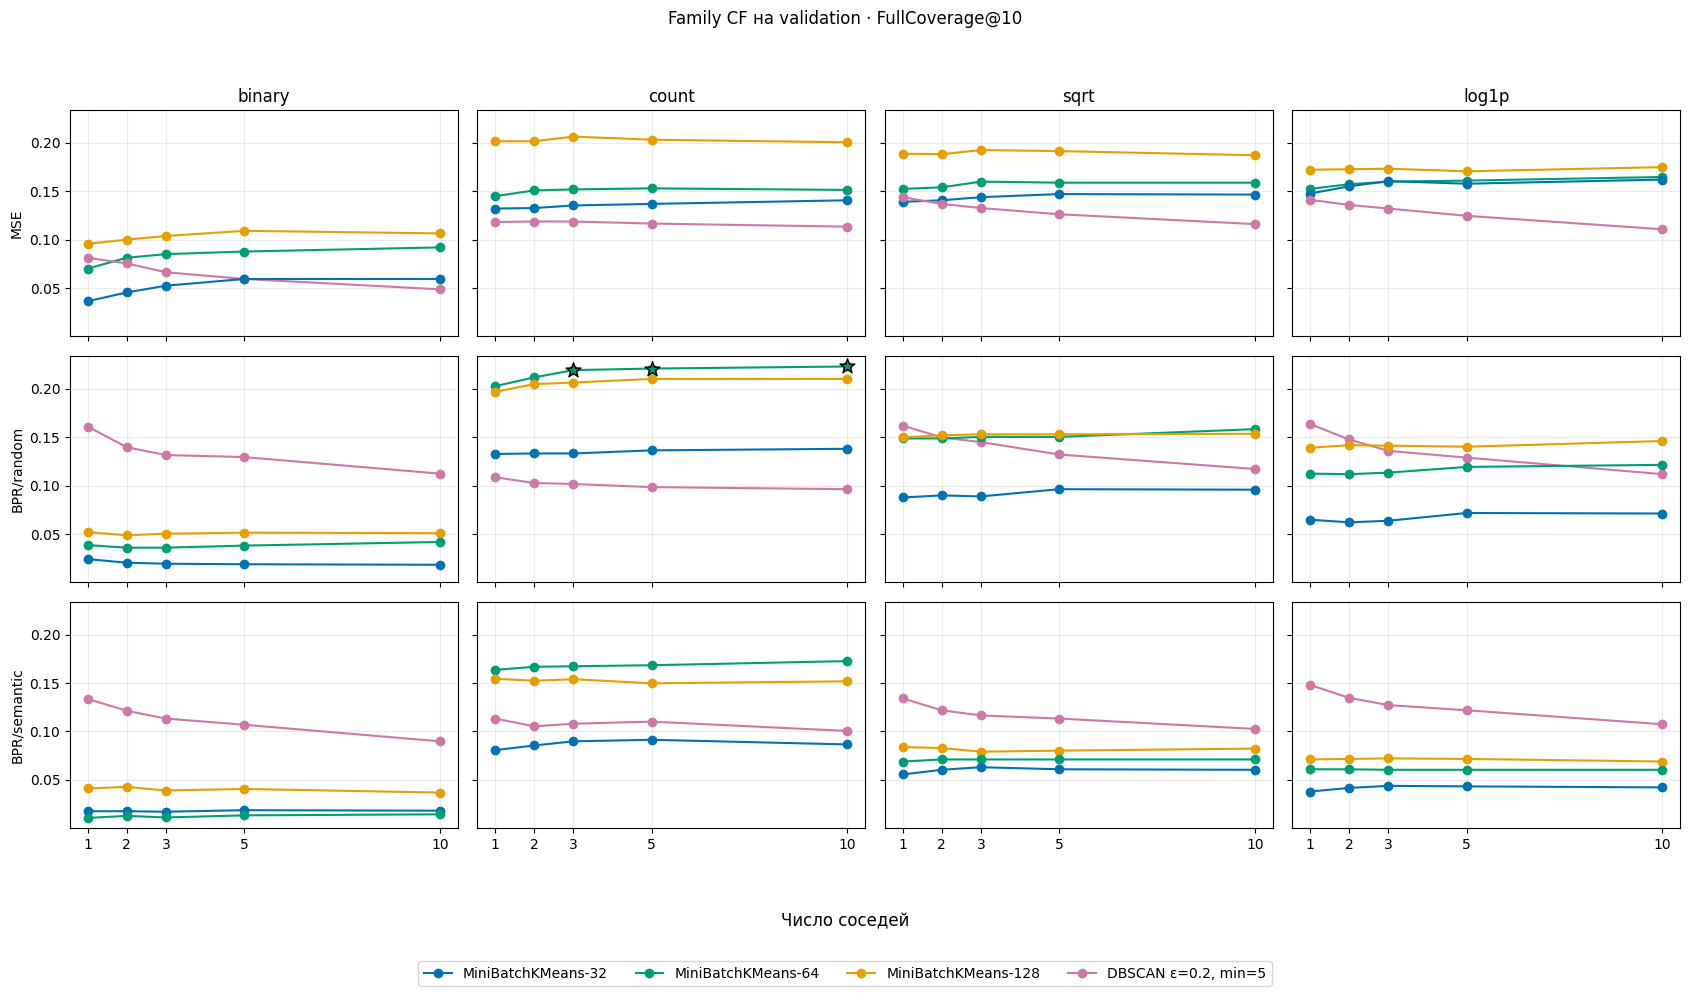

In [8]:
figure, axes = plt.subplots(len(CF_OBJECTIVES), len(FAMILY_RELEVANCE), figsize=(17, 10),
    sharex=True, sharey=True)
clustering_colors = dict(zip(FAMILY_CLUSTERINGS, ['#0072B2', '#009E73', '#E69F00', '#CC79A7']))
family_top_names = set(family_top.model)
for i, objective in enumerate(CF_OBJECTIVES):
    for j, relevance in enumerate(FAMILY_RELEVANCE):
        axis = axes[i, j]
        panel = family_validation_scores[(family_validation_scores.objective == objective)
                                         & (family_validation_scores.relevance == relevance)]
        for clustering, curve in panel.groupby('clustering', sort=False):
            curve = curve.sort_values('n_neighbors')
            color = clustering_colors[clustering]
            axis.plot(curve.n_neighbors, curve.FullCoverage, color=color, marker='o')
            selected = curve[curve.model.isin(family_top_names)]
            axis.scatter(selected.n_neighbors, selected.FullCoverage, color=color, marker='*',
                         edgecolor='black', s=125, zorder=3)
        if panel.empty:
            axis.text(.5, .5, 'Нет допустимых вариантов', transform=axis.transAxes, ha='center')
        if i == 0:
            axis.set_title(relevance)
        if j == 0:
            axis.set_ylabel(objective)
        axis.set_xticks(FAMILY_NEIGHBORS)
        axis.grid(alpha=.25)
from matplotlib.lines import Line2D
legend = [Line2D([], [], color=color, marker='o', label=clustering)
          for clustering, color in clustering_colors.items()]
figure.legend(handles=legend, loc='lower center', ncol=len(legend))
figure.suptitle('Family CF на validation · FullCoverage@10')
figure.supxlabel('Число соседей', y=.06)
figure.tight_layout(rect=(0, .09, 1, .95))
figure.savefig(RUN_DIR / 'family_validation.png', dpi=160, bbox_inches='tight')
display(figure); plt.close(figure)

## Обучение на train и ранжирование полного каталога

        Для итоговой оценки три выбранных Family CF повторно обучаются на том же train.
        Индикатор CF обновляется после каждой реальной эпохи. Общая стоимость BGE
        не включается повторно в каждую модель; fit/prepare/predict учитываются отдельно.

In [9]:
models, predictions, metric_rows, loss_rows, model_resources = {}, [], [], [], {}
catalogue = set(full_corpus)
for name, factory in tqdm(FACTORIES.items(), desc='Итоговое сравнение на test'):
    config = dict(CONFIGS[name])
    is_cf = VARIANTS[name]['loss'] is not None
    if name not in ['Popularity', 'BM25']:
        config['encoder'] = cached_encoder
    model = factory(**config)
    fit_kwargs = dict(train_queries=train_queries)
    if is_cf:
        fit_kwargs['train_query_embeddings'] = train_cache
        if config['loss'] == 'bpr' and config['negative_sampling'] == 'semantic':
            fit_kwargs['train_api_embeddings'] = train_api_cache
        with tqdm(total=config['epochs'], desc=name + ' эпохи') as bar:
            def on_epoch(epoch, loss):
                bar.update(epoch - bar.n)
                bar.set_postfix(loss=f'{loss:.6f}')
            with PeakRSS() as measurement:
                model.fit(train_corpus, train_qrels, progress_callback=on_epoch, **fit_kwargs)
    else:
        with PeakRSS() as measurement:
            model.fit(train_corpus, train_qrels, **fit_kwargs)
    fit_resource = measurement.record()
    with PeakRSS() as measurement:
        model.prepare_candidates(full_corpus)
    prepare_resource = measurement.record()
    rankings = []
    with PeakRSS() as measurement:
        for identifier, text in tqdm(test_queries.items(), desc=name + ' test', leave=False):
            ranking = model.predict_from_embedding(test_cache[identifier], 20) if is_cf else model.predict(text, 20)
            rankings.append((identifier, ranking))
    predict_resource = measurement.record()
    with PeakRSS() as measurement:
        for identifier, ranking in tqdm(rankings, desc=name + ' метрики', leave=False):
            if len(ranking) != min(20, len(catalogue)) or len(ranking) != len(set(ranking)) or not set(ranking) <= catalogue:
                raise ValueError('Недопустимое ранжирование полного каталога')
            predictions.append(dict(model=name, Request_id=identifier, ranked_api_ids=ranking))
            scores = query_metrics(ranking, test_qrels[identifier])
            if scores is not None:
                metric_rows.extend(dict(model=name, Request_id=identifier, metric=metric, k=k, value=value)
                                   for (metric, k), value in scores.items())
    evaluate_resource = measurement.record()
    model_resources[name] = dict(fit=fit_resource, prepare_candidates=prepare_resource,
        predict=predict_resource, evaluate=evaluate_resource)
    if is_cf:
        loss_rows.extend(dict(model=name, **VARIANTS[name], epoch=epoch, value=value)
                         for epoch, value in enumerate(model.loss_history_, 1))
    models[name] = model
per_query = pd.DataFrame(metric_rows)
losses = pd.DataFrame(loss_rows)
summary = per_query.groupby(['model','metric','k'], as_index=False).value.mean()
pd.DataFrame(predictions).to_json(RUN_DIR / 'predictions.jsonl', orient='records', lines=True)
per_query.to_parquet(RUN_DIR / 'per_query_metrics.parquet', index=False)
summary.to_csv(RUN_DIR / 'summary_curves.csv', index=False)
losses.to_csv(RUN_DIR / 'losses.csv', index=False)
display(summary[summary.k.isin([3,5,10,20])].pivot(index=['model','k'], columns='metric', values='value').round(4))

Итоговое сравнение на test:   0%|          | 0/12 [00:00<?, ?it/s]

Popularity test:   0%|          | 0/1877 [00:00<?, ?it/s]

Popularity метрики:   0%|          | 0/1877 [00:00<?, ?it/s]

BM25 test:   0%|          | 0/1877 [00:00<?, ?it/s]

BM25 метрики:   0%|          | 0/1877 [00:00<?, ?it/s]

BGE test:   0%|          | 0/1877 [00:00<?, ?it/s]

... (25 outputs left out)

Family CF | MiniBatchKMeans-64 | count | BPR/random | n=3 эпохи:   0%|          | 0/5 [00:00<?, ?it/s]

Family CF | MiniBatchKMeans-64 | count | BPR/random | n=3 test:   0%|          | 0/1877 [00:00<?, ?it/s]

Family CF | MiniBatchKMeans-64 | count | BPR/random | n=3 метрики:   0%|          | 0/1877 [00:00<?, ?it/s]

metric                                                 FullCoverage    NDCG  \
model                                              k                          
BGE                                                3         0.0773  0.2945   
                                                   5         0.1119  0.3310   
                                                   10        0.1747  0.3720   
                                                   20        0.2621  0.4090   
BM25                                               3         0.0527  0.2695   
                                                   5         0.0836  0.2980   
                                                   10        0.1193  0.3245   
                                                   20        0.1689  0.3493   
Family CF | MiniBatchKMeans-64 | count | BPR/ra... 3         0.0346  0.3955   
                                                   5         0.0874  0.4436   
                                                   10        0.2067  0.4956   
                                                   20        0.3937  0.5406   
Family CF | MiniBatchKMeans-64 | count | BPR/ra... 3         0.0336  0.3865   
                                                   5         0.0852  0.4347   
                                                   10        0.2072  0.4869   
                                                   20        0.3751  0.5302   
Family CF | MiniBatchKMeans-64 | count | BPR/ra... 3         0.0336  0.3911   
                                                   5         0.0858  0.4397   
                                                   10        0.2099  0.4924   
                                                   20        0.3836  0.5361   
Popularity                                         3         0.0000  0.1611   
                                                   5         0.0000  0.1778   
                                                   10        0.0069  0.2075   
                                                   20        0.0128  0.2388   
Projected CF | BPR/random                          3         0.1119  0.5036   
                                                   5         0.2818  0.5857   
                                                   10        0.5812  0.6638   
                                                   20        0.8348  0.7034   
Projected CF | BPR/semantic                        3         0.0091  0.2143   
                                                   5         0.0197  0.2501   
                                                   10        0.0559  0.2938   
                                                   20        0.1454  0.3357   
Projected CF | MSE                                 3         0.0202  0.4012   
                                                   5         0.0490  0.4285   
                                                   10        0.1454  0.4705   
                                                   20        0.3037  0.5051   
Query-KNN CF | BPR/random                          3         0.2477  0.6773   
                                                   5         0.5162  0.7497   
                                                   10        0.7421  0.7933   
                                                   20        0.8514  0.8094   
Query-KNN CF | BPR/semantic                        3         0.0810  0.4358   
                                                   5         0.1742  0.4948   
                                                   10        0.3133  0.5457   
                                                   20        0.4869  0.5856   
Query-KNN CF | MSE                                 3         0.0181  0.4374   
                                                   5         0.0506  0.4712   
                                                   10        0.1657  0.5098   
                                                   20        0.4390  0.5577   

metric                                           

## Парная неопределённость и покрытие

        Все модели используют одни и те же bootstrap-веса. Помимо query-bootstrap,
        при наличии близких компонент показываем cluster-bootstrap целых групп.
        Покрытие полного каталога и train-истории учитывается раздельно.

In [10]:
selected_metrics = per_query[per_query.k.isin([3,5,10,20])]
interval_frames = []
modes = [('query', None)]
if (group_sizes > 1).any():
    modes.append(('group', groups))
with PeakRSS() as measurement:
    for mode, resample_groups in tqdm(modes, desc='Парный bootstrap ×1000'):
        frame = bootstrap_metrics(selected_metrics, n_bootstrap=1000, seed=68, groups=resample_groups)
        frame['resampling'] = mode
        interval_frames.append(frame)
resources['bootstrap'] = measurement.record()
intervals = pd.concat(interval_frames, ignore_index=True)
intervals.to_csv(RUN_DIR / 'intervals_and_paired_differences.csv', index=False)
covered = []
for identifier, positives in test_qrels.items():
    if positives:
        covered.append(dict(Request_id=identifier, positives=len(positives),
            full_found=len(positives & catalogue), train_found=len(positives & train_api_ids)))
coverage_rows = pd.DataFrame(covered)
coverage = dict(full_catalogue_size=len(catalogue), train_history_size=len(train_api_ids),
    test_queries=len(test_queries), evaluated_queries=len(covered),
    excluded_no_positive_queries=sum(not value for value in test_qrels.values()),
    full_catalogue_micro=coverage_rows.full_found.sum()/coverage_rows.positives.sum(),
    full_catalogue_macro=(coverage_rows.full_found/coverage_rows.positives).mean(),
    train_history_micro=coverage_rows.train_found.sum()/coverage_rows.positives.sum(),
    train_history_macro=(coverage_rows.train_found/coverage_rows.positives).mean())
coverage_rows.to_csv(RUN_DIR / 'coverage_by_query.csv', index=False)
display(pd.DataFrame([coverage]))
display(intervals[(intervals.k == 10) & (intervals.metric == 'FullCoverage')].round(4))

Парный bootstrap ×1000:   0%|          | 0/2 [00:00<?, ?it/s]

,full_catalogue_size,train_history_size,test_queries,evaluated_queries,excluded_no_positive_queries,full_catalogue_micro,full_catalogue_macro,train_history_micro,train_history_macro
0,464,464,1877,1877,0,1.0,1.0,1.0,1.0


,model,metric,k,mean,low,high,difference,delta_low,delta_high,resampling
8,Popularity,FullCoverage,10,0.0069,0.0032,0.0107,-0.1678,-0.1849,-0.1497,query
20,BM25,FullCoverage,10,0.1193,0.1049,0.1343,-0.0554,-0.0709,-0.0410,query
32,BGE,FullCoverage,10,0.1747,0.1572,0.1918,0.0000,0.0000,0.0000,query
44,Query-KNN CF | MSE,FullCoverage,10,0.1657,0.1492,0.1833,-0.0091,-0.0336,0.0149,query
56,Query-KNN CF | BPR/random,FullCoverage,10,0.7421,0.7224,0.7624,0.5674,0.5450,0.5930,query
68,Query-KNN CF | BPR/semantic,FullCoverage,10,0.3133,0.2919,0.3340,0.1385,0.1151,0.1636,query
80,Projected CF | MSE,FullCoverage,10,0.1454,0.1295,0.1609,-0.0293,-0.0533,-0.0064,query
92,Projected CF | BPR/random,FullCoverage,10,0.5812,0.5599,0.6026,0.4065,0.3809,0.4310,query
104,Projected CF | BPR/semantic,FullCoverage,10,0.0559,0.0458,0.0671,-0.1188,-0.1364,-0.1012,query
116,Family CF | MiniBatchKMeans-64 | count | BPR/r...,FullCoverage,10,0.2067,0.1886,0.2243,0.0320,0.0106,0.0544,query


## Кривые качества и реальные функции потерь

        Общий test-рисунок содержит три бейзлайна, по три варианта Query-KNN CF
        и Projected CF, а также топ-3 Family CF из validation. Слева Recall@K,
        в центре NDCG@K, справа FullCoverage@K. Ось X — K от 1 до 20.
        Цвет обозначает семейство модели; для CF сплошная линия означает MSE,
        штриховая — BPR/random, точечная — BPR/semantic. Легенда общая для трёх панелей.
        Три варианта Family различаются также маркерами, поскольку loss может совпасть.
        Если метрики какой-либо конфигурации ещё не рассчитаны, код сообщает об этом
        вместо молчаливого построения неполного сравнения.
        Истории MSE и BPR показаны на разных осях: их абсолютные значения несопоставимы.
        В loss-таблице тип цели хранится в loss, а её численное значение — в value.

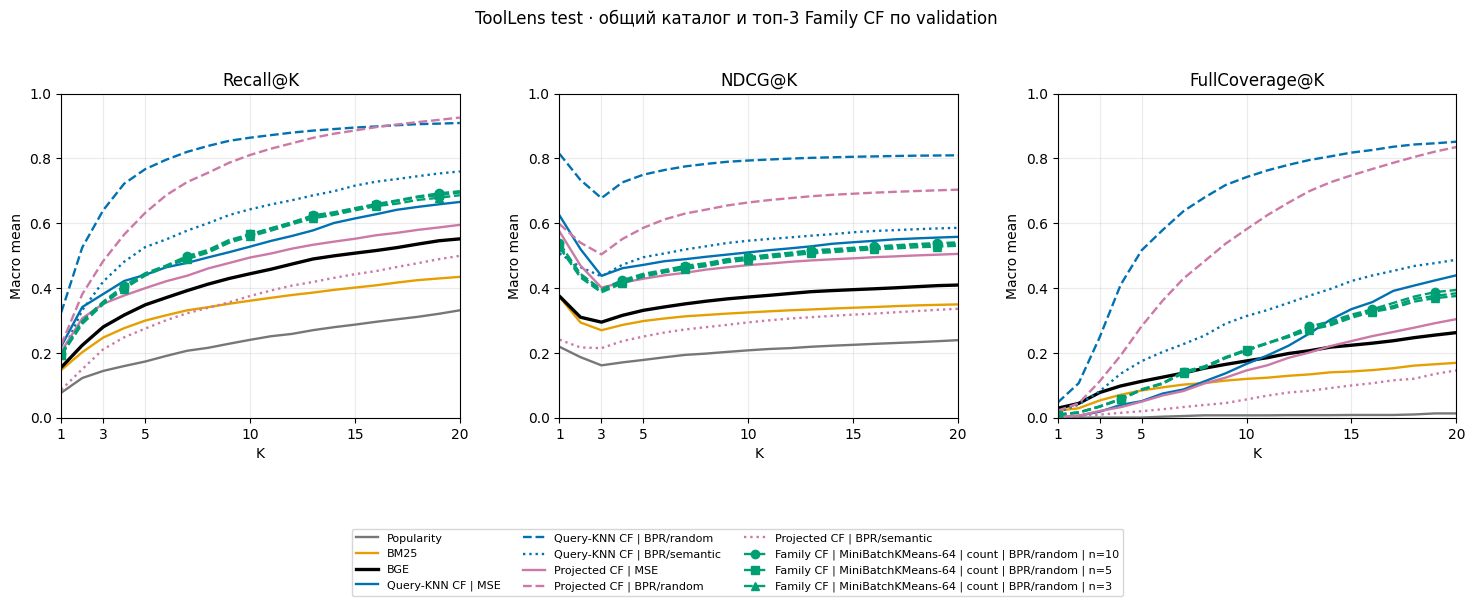

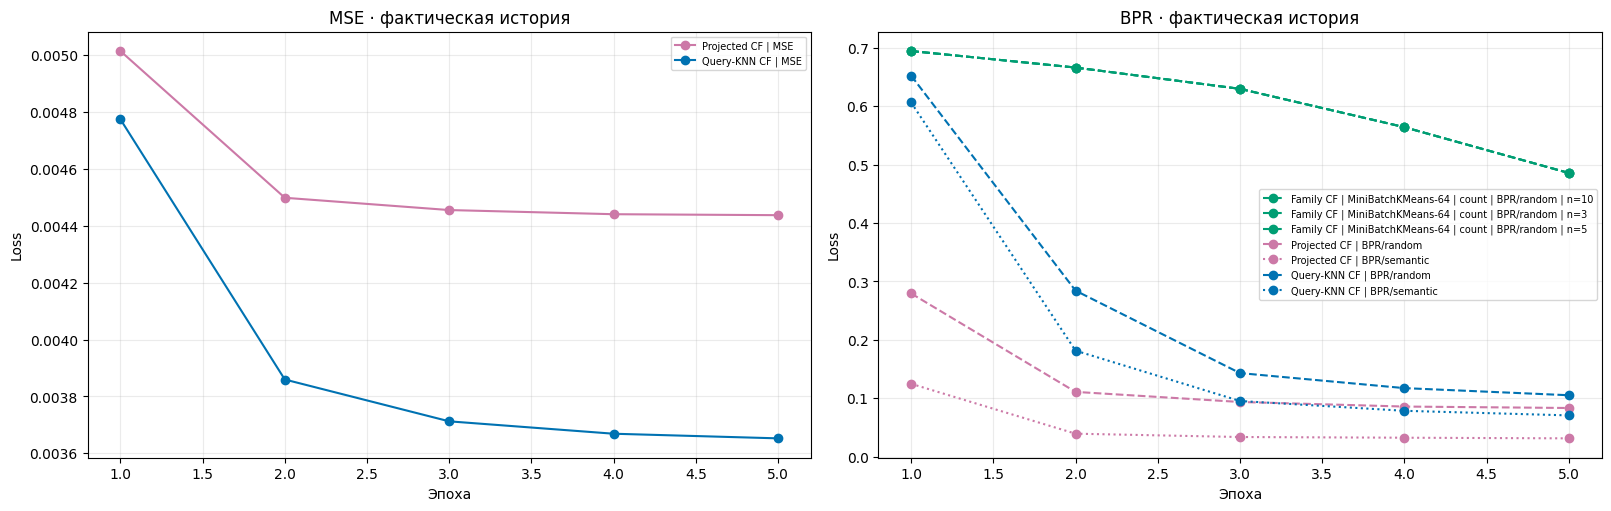

In [11]:
model_order = list(FACTORIES)
missing_models = set(model_order) - set(summary['model'])
if missing_models:
    raise ValueError('Ещё не рассчитаны метрики конфигураций: ' + ', '.join(sorted(missing_models)))
family_colors = {
    'Popularity': '#777777', 'BM25': '#E69F00', 'BGE': '#000000',
    'Query-KNN CF': '#0072B2', 'Family CF': '#009E73', 'Projected CF': '#CC79A7',
}
objective_styles = {('mse', None): '-', ('bpr', 'random'): '--', ('bpr', 'semantic'): ':'}
family_markers = dict(zip(family_top.model, ('o', 's', '^')))
metric_panels = [('Recall', 'Recall@K'), ('NDCG', 'NDCG@K'), ('FullCoverage', 'FullCoverage@K')]
figure, axes = plt.subplots(1, 3, figsize=(18,6))
figure.subplots_adjust(bottom=.30, top=.84, wspace=.25)
for axis, (metric, title) in zip(axes, metric_panels):
    for name in model_order:
        curve = summary[(summary.model == name) & (summary.metric == metric)].sort_values('k')
        if len(curve) != 20 or set(curve.k) != set(range(1,21)):
            raise ValueError(f'Неполная кривая {metric} для {name}: нужны K=1…20')
        variant = VARIANTS[name]
        style = objective_styles.get((variant['loss'], variant['negative_sampling']), '-')
        axis.plot(curve.k, curve.value, color=family_colors[variant['family']],
            linestyle=style, linewidth=2.4 if name == 'BGE' else 1.7,
            marker=family_markers.get(name), markevery=3, label=name)
    axis.set(title=title, xlabel='K', ylabel='Macro mean', xlim=(1,20), ylim=(0,1))
    axis.set_xticks([1,3,5,10,15,20])
    axis.grid(alpha=.25)
handles, labels = axes[0].get_legend_handles_labels()
figure.legend(handles, labels, loc='lower center', ncol=3, fontsize=8)
figure.suptitle('ToolLens test · общий каталог и топ-3 Family CF по validation')
figure.savefig(RUN_DIR / 'all_models_metrics.png', dpi=160, bbox_inches='tight')
display(figure)
plt.close(figure)
figure, axes = plt.subplots(1, 2, figsize=(16,5), constrained_layout=True)
for axis, objective in zip(axes, ['mse', 'bpr']):
    for name, curve in losses[losses.loss == objective].groupby('model'):
        curve = curve.sort_values('epoch')
        variant = VARIANTS[name]
        style = objective_styles[(variant['loss'], variant['negative_sampling'])]
        axis.plot(curve.epoch, curve.value, marker='o', linestyle=style,
            color=family_colors[variant['family']], label=name)
    axis.set(title=objective.upper() + ' · фактическая история', xlabel='Эпоха', ylabel='Loss')
    axis.legend(fontsize=7); axis.grid(alpha=.25)
figure.savefig(RUN_DIR / 'cf_losses.png', dpi=160)
display(figure); plt.close(figure)

## Manifest и ограничения

        Сохранены все предсказания, метрики по запросам, доверительные интервалы,
        конфигурации, ID групп и split, хэши данных/кода/весов, время и выборочный RSS.
        Используются готовые сплиты ToolLens из processed/requests.parquet.
        Семейства отбираются по val. В прошлом эксперименте был другой test,
        поэтому сравнивать метрики двух запусков напрямую нельзя.
        Неполная разметка ограничивает интерпретацию; offline-метрики не доказывают успех LLM-агента.

In [12]:
import importlib.metadata
source_paths = list((ROOT / 'rankers').glob('*.py')) + [ROOT / 'experiments/toollens_experiment.py',
    ROOT / 'experiments/toollens_family_validation.py', ROOT / 'experiments/build_toollens_notebook.py',
    ROOT / 'experiments/run_notebook.py']
source_hashes = {str(path.relative_to(ROOT)): file_sha256(path) for path in source_paths}
model_hashes = {str(path.relative_to(MODEL_PATH)): file_sha256(path)
                for path in sorted(MODEL_PATH.rglob('*')) if path.is_file()}
notebook_source = json.loads((ROOT / 'experiments/toollens_family_minibatch.ipynb').read_text())
code_cells_hash = json_hash([cell['source'] for cell in notebook_source['cells'] if cell['cell_type'] == 'code'])
manifest = dict(protocol=PROTOCOL, real_data=True, seed=SEED, bootstrap_seed=68,
    bootstrap_resamples=1000, frozen_configs=CONFIGS,
    model_variants=VARIANTS,
    family_search_space=family_plan, family_selection=family_selection,
    split_hash=split_hash, split_report=split_report, data_hashes=data_hashes, source_hashes=source_hashes,
    model_hashes=model_hashes, notebook_code_hash=code_cells_hash,
    git_head=subprocess.check_output(['git','rev-parse','HEAD'], cwd=ROOT, text=True).strip(),
    python=sys.version, platform=platform.platform(), threads=4,
    versions={name: importlib.metadata.version(name) for name in
              ['numpy','pandas','scipy','scikit-learn','torch','sentence-transformers','transformers']},
    encoder_revision='local-files-hashed', query_instruction=INSTRUCTION,
    validation=validation, coverage=coverage, resources=resources, models=model_resources,
    created_utc=datetime.now(timezone.utc).isoformat(), run_directory=str(RUN_DIR))
(RUN_DIR / 'manifest.json').write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding='utf-8')
display(pd.DataFrame([dict(model=name, stage=stage, **values)
    for name, stages in model_resources.items() for stage, values in stages.items()]))
print('Артефакты:', RUN_DIR)
print('Топ-3 зафиксирован по validation до оценки на test.')

,model,stage,seconds,baseline_rss_bytes,peak_rss_bytes,peak_increase_bytes,sampling_interval_seconds
0,Popularity,fit,0.023798,734085120,734150656,65536,0.02
1,Popularity,prepare_candidates,0.000526,734117888,734150656,32768,0.02
2,Popularity,predict,0.004847,734117888,734724096,606208,0.02
3,Popularity,evaluate,0.608497,734691328,1029505024,294813696,0.02
4,BM25,fit,0.032649,1029472256,1033191424,3719168,0.02
5,BM25,prepare_candidates,0.020002,1033158656,1035288576,2129920,0.02
6,BM25,predict,0.087188,1035255808,1035419648,163840,0.02
7,BM25,evaluate,0.417899,1035386880,1059799040,24412160,0.02
8,BGE,fit,0.027686,1059782656,1062141952,2359296,0.02
9,BGE,prepare_candidates,0.001908,1062109184,1062830080,720896,0.02


Артефакты: /Users/svatoslavpolonskiy/Codex/CFTSagent/output/jupyter-notebook/runs/20261119T090314Z_f80bbec0
Топ-3 зафиксирован по validation до оценки на test.


## Все варианты Family CF: Recall, NDCG и FullCoverage

        На каждой панели по одной линии для каждой конфигурации с метриками на `val`.
        Цвет обозначает кластеризацию, стиль линии — MSE, BPR/random или BPR/semantic.
        Маркерами выделены три варианта, выбранные для общей оценки на `test`.
        Значения каждой кривой доступны в `family_validation_curves.csv`.

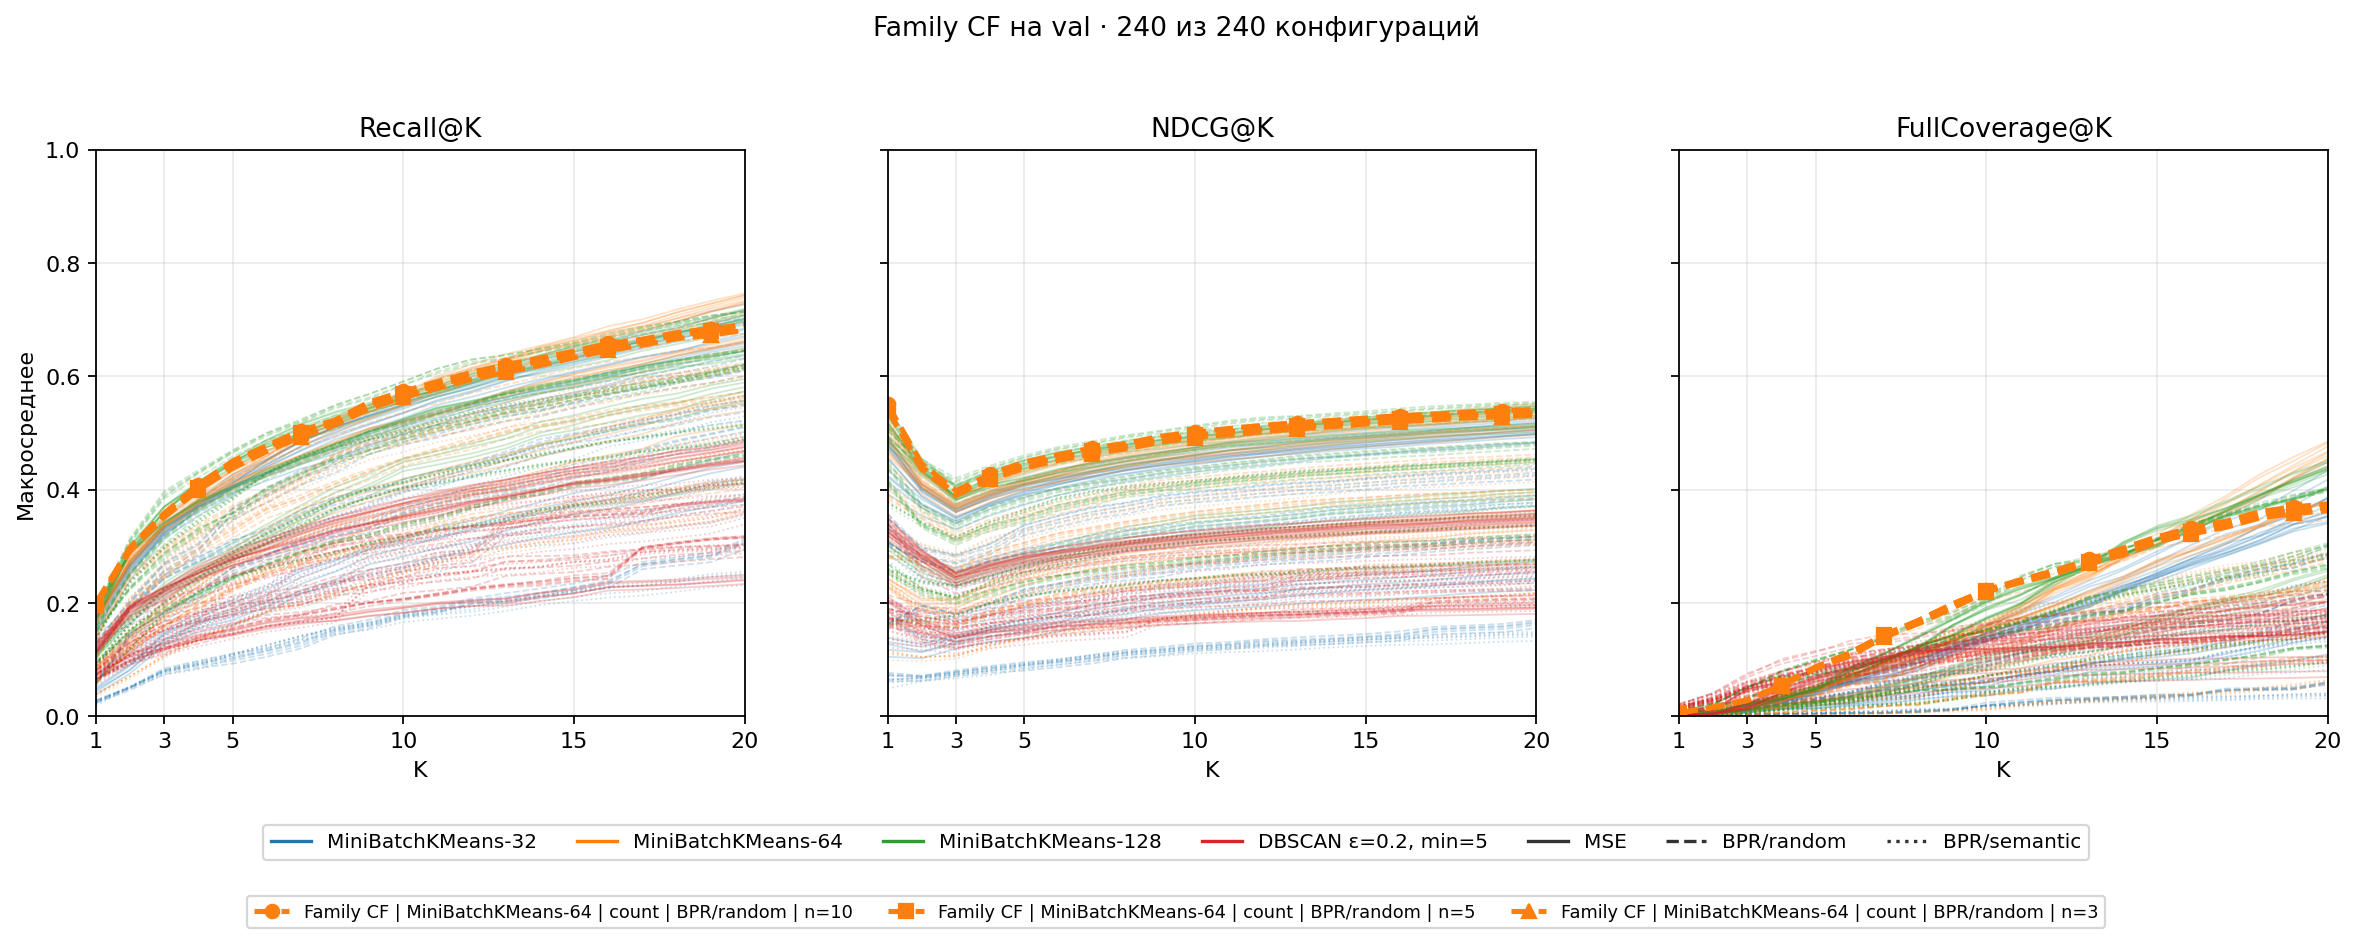

In [ ]:
from experiments.toollens_family_validation import plot_family_validation_curves

family_curves = pd.read_csv(RUN_DIR / 'family_validation_curves.csv')
planned_count = len(FAMILY_FIT_CONFIGS) * len(FAMILY_NEIGHBORS)
figure = plot_family_validation_curves(family_curves, family_top.model, planned_count)
figure.savefig(RUN_DIR / 'family_all_metrics_lines.png', dpi=160, bbox_inches='tight')
display(figure)
plt.close(figure)